In [1]:
import readgadget

In [2]:
import numpy as np
from pathlib import Path

In [3]:
ddir = "/Users/suqikuai777/Dataspace/Quijote"

In [4]:
snapshot = f"{ddir}/snapdir_004/snap_004"

In [5]:
ptype = [1]

In [6]:
# read header
header   = readgadget.header(snapshot)
BoxSize  = header.boxsize/1e3  #Mpc/h
Nall     = header.nall         #Total number of particles
Masses   = header.massarr*1e10 #Masses of the particles in Msun/h
Omega_m  = header.omega_m      #value of Omega_m
Omega_l  = header.omega_l      #value of Omega_l
h        = header.hubble       #value of h
redshift = header.redshift     #redshift of the snapshot
Hubble   = 100.0*np.sqrt(Omega_m*(1.0+redshift)**3+Omega_l)#Value of H(z) in km/s/(Mpc/h)

In [7]:
print(BoxSize, Omega_m, h, redshift)

1000.0 0.3175 0.6711 2.220446049250313e-16


In [8]:
# read positions, velocities and IDs of the particles
pos = readgadget.read_block(snapshot, "POS ", ptype)/1e3 #positions in Mpc/h
# vel = readgadget.read_block(snapshot, "VEL ", ptype)     #peculiar velocities in km/s
# ids = readgadget.read_block(snapshot, "ID  ", ptype)-1   #IDs starting from 0

In [9]:
vel = readgadget.read_block(snapshot, "VEL ", ptype)     #peculiar velocities in km/s

In [10]:
pos.shape

(134217728, 3)

In [11]:
f_halo = f"{ddir}/out_4_pid.list"

In [12]:
data = np.loadtxt(f_halo)

In [13]:
from matplotlib import pyplot as plt

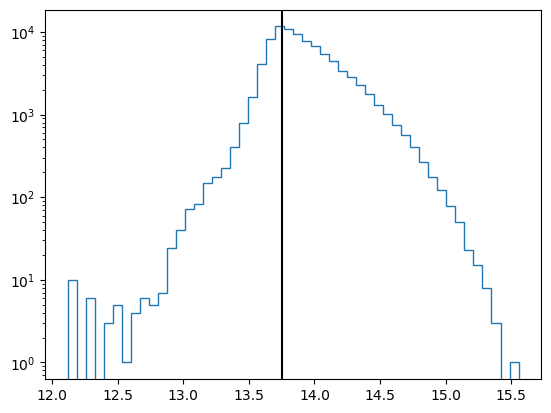

In [14]:
plt.hist(np.log10(data[:,2]), bins=50, log=True, histtype='step');
plt.axvline(13.75, c='k')

In [15]:
data_cut = data[np.log10(data[:,2])>13.75]

In [16]:
len(data_cut)

63215

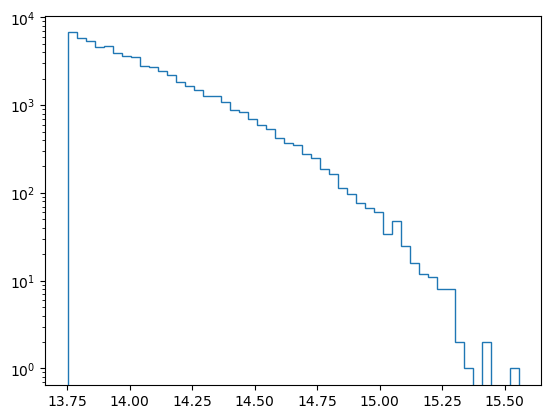

In [17]:
plt.hist(np.log10(data_cut[:,2]), bins=50, log=True, histtype='step');

In [18]:
np.savetxt(f"{ddir}/halo_complete_pos.txt", data_cut[:,8:11])

In [18]:
halo_pos = data_cut[:,8:11]
halo_vel = data_cut[:,11:14]

In [165]:
import MAS_library as MASL

# density field parameters
grid    = 256    #the 3D field will have grid x grid x grid voxels
BoxSize = 1000.0 #Mpc/h ; size of box
MAS     = 'CIC'  #mass-assigment scheme
verbose = True   #print information on progress

# define 3D density field
num = np.zeros((grid,grid,grid), dtype=np.float32)

# construct 3D density field
MASL.MA(pos.astype(np.float32), num, BoxSize, MAS, verbose=verbose)

# at this point, delta contains the effective number of particles in each voxel
# now compute overdensity and density constrast
delta = num / np.mean(num, dtype=np.float64);  delta -= 1.0


Using CIC mass assignment scheme
Time taken = 1.242 seconds



In [92]:
vel_map_z_truth = np.zeros((grid, grid, grid), dtype=np.float32)
MASL.MA(pos.astype(np.float32), vel_map_z_truth, BoxSize, MAS, W=vel[:,2].astype(np.float32), verbose=verbose)


Using CIC mass assignment scheme with weights
Time taken = 1.389 seconds



In [131]:
vel_map_z_truth /= num

In [61]:
def linear_velocity(delta, L, f, aH, R_smooth=None):
    """
    delta    : real overdensity field, shape (N, N, N)
    L        : box size in Mpc/h
    f        : linear growth rate, ~ Omega_m(z)**0.55 in LCDM
               (use beta = f/b if delta is a galaxy field with bias b)
    aH       : a*H(z) in km/s per (Mpc/h), i.e. 100 * a * E(z)
    R_smooth : optional Gaussian smoothing scale in Mpc/h
    returns  : (vx, vy, vz) in km/s
    """
    N = delta.shape[0]
    dk = np.fft.rfftn(delta)

    kx = 2*np.pi*np.fft.fftfreq(N, d=L/N)
    kz = 2*np.pi*np.fft.rfftfreq(N, d=L/N)       # halved axis
    KX, KY, KZ = np.meshgrid(kx, kx, kz, indexing="ij", sparse=True)

    k2 = KX**2 + KY**2 + KZ**2
    k2[0, 0, 0] = 1.0           # avoid divide-by-zero
    dk[0, 0, 0] = 0.0           # mean density carries no velocity

    if R_smooth is not None:
        dk = dk * np.exp(-0.5 * k2 * R_smooth**2)

    # Zero the Nyquist frequency in each derivative: i*k_Nyq has no
    # Hermitian partner, so it would inject a spurious imaginary part.
    kx_d, kz_d = kx.copy(), kz.copy()
    if N % 2 == 0:
        kx_d[N//2] = 0.0
        kz_d[-1] = 0.0
    KXd, KYd, KZd = np.meshgrid(kx_d, kx_d, kz_d, indexing="ij", sparse=True)

    pref = 1j * aH * f * dk / k2
    
    return tuple(np.fft.irfftn(pref * K, s=delta.shape) for K in (KXd, KYd, KZd))

In [66]:
f = Omega_m**0.55
L = BoxSize
aH = 100.0

In [111]:
vel_map_x_recon, vel_map_y_recon, vel_map_z_recon = linear_velocity(delta, L, f, aH, R_smooth=3.0)

/var/folders/pq/qhkr3j_j1cs26rpp76qg2_l80000gn/T/ipykernel_12990/3527873624.py:35: DeprecationWarning: `axes` should not be `None` if `s` is not `None` (Deprecated in NumPy 2.0). In a future version of NumPy, this will raise an error and `s[i]` will correspond to the size along the transformed axis specified by `axes[i]`. To retain current behaviour, pass a sequence [0, ..., k-1] to `axes` for an array of dimension k.
  return tuple(np.fft.irfftn(pref * K, s=delta.shape) for K in (KXd, KYd, KZd))


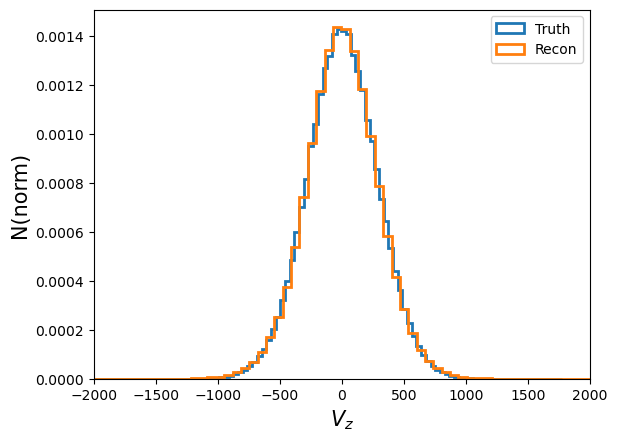

In [132]:
plt.hist((vel_map_z_truth).ravel(), bins=100, density=True, lw=2, histtype='step', label='Truth');
plt.hist(vel_map_z_recon.ravel(), bins=100, density=True, lw=2, histtype='step', label='Recon');
plt.legend()
plt.xlim(-2000, 2000)
plt.xlabel(r'$V_{z}$', fontsize=15);
plt.ylabel('N(norm)', fontsize=15);

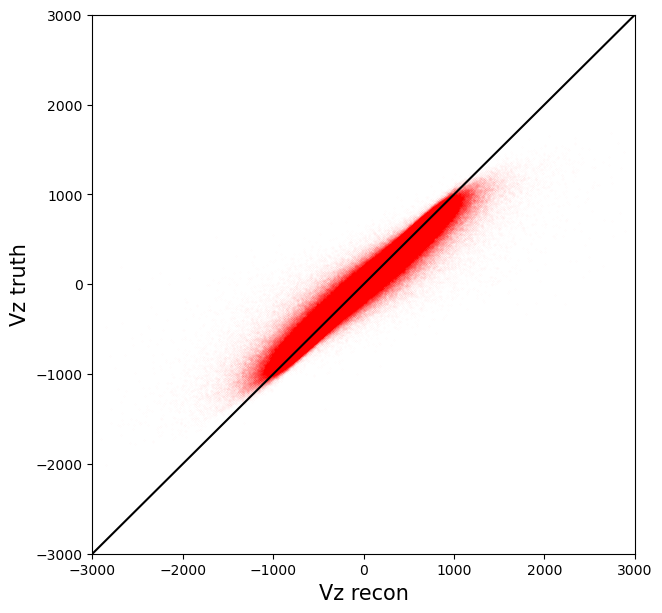

In [139]:
fig = plt.figure(figsize=(7,7))
plt.scatter(vel_map_z_recon.ravel(), vel_map_z_truth.ravel(), s=0.001, marker='.', alpha=0.5, c='r')
plt.plot([-3000,3000], [-3000,3000], c='k')
plt.xlabel('Vz recon', fontsize=15)
plt.ylabel('Vz truth', fontsize=15)
plt.xlim(-3000,3000)
plt.ylim(-3000, 3000);

In [215]:
# define 3D density field
num_h = np.zeros((grid,grid,grid), dtype=np.float32)

# construct 3D density field
MASL.MA(data_cut[:,8:11].astype(np.float32), num_h, BoxSize, MAS, verbose=verbose)

# at this point, delta contains the effective number of particles in each voxel
# now compute overdensity and density constrast
delta_h = num_h / np.mean(num_h, dtype=np.float64);  delta_h -= 1.0


Using CIC mass assignment scheme
Time taken = 0.004 seconds



In [223]:
import Pk_library as PKL

# compute power spectrum
Pk = PKL.XPk([delta_h.astype(np.float32), delta.astype(np.float32)], BoxSize, axis=0, MAS=[MAS, MAS], threads=1)

# Pk is a python class containing the 1D, 2D and 3D power spectra, that can be retrieved as

# 3D P(k)
k       = Pk.k3D
XPk     = Pk.XPk[:,0]
Nmodes  = Pk.Nmodes3D


Computing power spectra of the fields...
Time FFTS = 0.30
Time loop = 0.17
Time taken = 0.47 seconds


In [221]:
# compute power spectrum
Pk = PKL.Pk(delta.astype(np.float32), BoxSize, axis=0, MAS=MAS, threads=1)

# Pk is a python class containing the 1D, 2D and 3D power spectra, that can be retrieved as

# 3D P(k)
k       = Pk.k3D
Pk0_auto     = Pk.Pk[:,0] #monopole


Computing power spectrum of the field...
Time to complete loop = 0.36
Time taken = 0.52 seconds


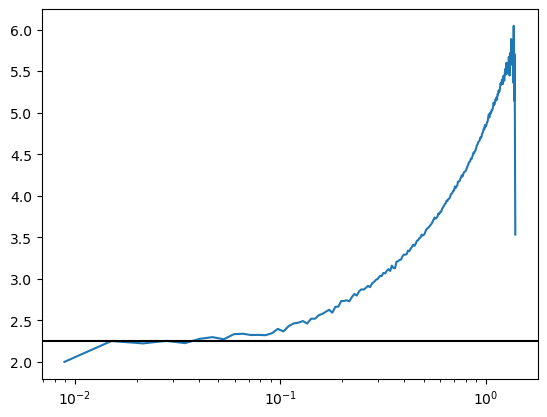

In [229]:
# plt.loglog(k, Pk0_auto)
plt.semilogx(k, XPk[:,0]/Pk0_auto)
plt.axhline(2.25, c='k')
# plt.ylim(1.9, 3)

In [249]:
f = Omega_m**0.55
L = BoxSize
aH = 100.0
b = 2.25

vel_map_x_recon_h, vel_map_y_recon_h, vel_map_z_recon_h = linear_velocity(delta_h, L, f/b, aH, R_smooth=5.0)

/var/folders/pq/qhkr3j_j1cs26rpp76qg2_l80000gn/T/ipykernel_12990/3527873624.py:35: DeprecationWarning: `axes` should not be `None` if `s` is not `None` (Deprecated in NumPy 2.0). In a future version of NumPy, this will raise an error and `s[i]` will correspond to the size along the transformed axis specified by `axes[i]`. To retain current behaviour, pass a sequence [0, ..., k-1] to `axes` for an array of dimension k.
  return tuple(np.fft.irfftn(pref * K, s=delta.shape) for K in (KXd, KYd, KZd))


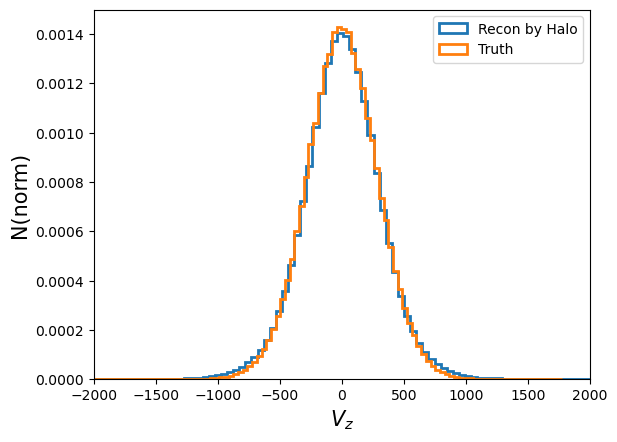

In [250]:
plt.hist(vel_map_z_recon_h.ravel(), bins=100, density=True, lw=2, histtype='step', label='Recon by Halo');
plt.hist((vel_map_z_truth).ravel(), bins=100, density=True, lw=2, histtype='step', label='Truth');
plt.legend()
plt.xlim(-2000, 2000)
plt.xlabel(r'$V_{z}$', fontsize=15);
plt.ylabel('N(norm)', fontsize=15);

/var/folders/pq/qhkr3j_j1cs26rpp76qg2_l80000gn/T/ipykernel_12990/3527873624.py:35: DeprecationWarning: `axes` should not be `None` if `s` is not `None` (Deprecated in NumPy 2.0). In a future version of NumPy, this will raise an error and `s[i]` will correspond to the size along the transformed axis specified by `axes[i]`. To retain current behaviour, pass a sequence [0, ..., k-1] to `axes` for an array of dimension k.
  return tuple(np.fft.irfftn(pref * K, s=delta.shape) for K in (KXd, KYd, KZd))


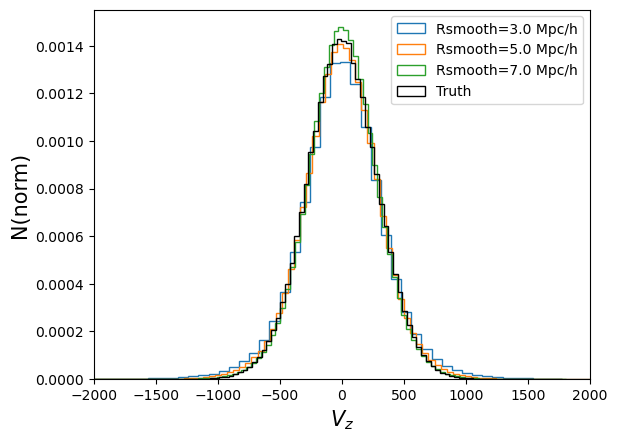

In [248]:
for iR_smooth in [3.0, 5.0, 7.0]:
    vel_map_x_recon_h, vel_map_y_recon_h, vel_map_z_recon_h = linear_velocity(delta_h, L, f/b, aH, R_smooth=iR_smooth)
    plt.hist(vel_map_z_recon_h.ravel(), bins=100, density=True, lw=1, histtype='step', label='Rsmooth={:.1f} Mpc/h'.format(iR_smooth));
plt.hist((vel_map_z_truth).ravel(), bins=100, density=True, lw=1, color='k', histtype='step', label='Truth');
plt.legend()
plt.xlim(-2000, 2000)
plt.xlabel(r'$V_{z}$', fontsize=15);
plt.ylabel('N(norm)', fontsize=15);

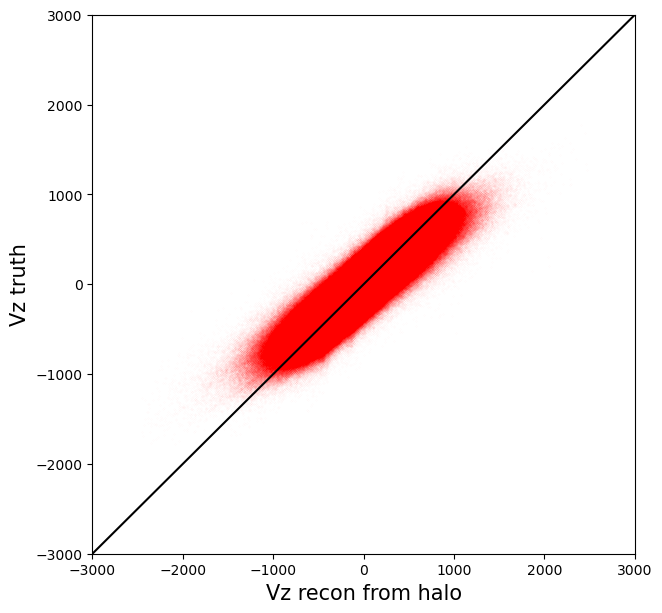

In [252]:
fig = plt.figure(figsize=(7,7))
plt.scatter(vel_map_z_recon_h.ravel(), vel_map_z_truth.ravel(), s=0.001, marker='.', alpha=0.5, c='r')
plt.plot([-3000,3000], [-3000,3000], c='k')
plt.xlabel('Vz recon from halo', fontsize=15)
plt.ylabel('Vz truth', fontsize=15)
plt.xlim(-3000,3000)
plt.ylim(-3000, 3000);

In [24]:
voids = np.loadtxt(f"{ddir}/void_complete.txt")

In [25]:
1./np.cbrt(len(voids)/1e9)

np.float64(13.271957076320627)

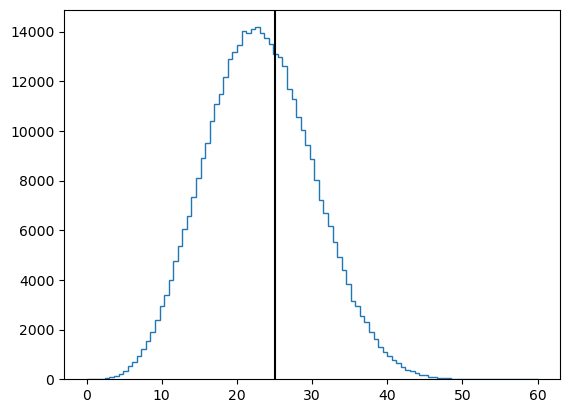

In [26]:
plt.hist(voids[:,3], bins=np.linspace(0, 60, 100), histtype='step');
plt.axvline(25, c='k')

In [27]:
lvoids = voids[voids[:,3]>27]

In [28]:
# define 3D density field
delta_v = np.zeros((grid,grid,grid), dtype=np.float32)

# construct 3D density field
MASL.MA(lvoids[:,:3].astype(np.float32), delta_v, BoxSize, MAS, verbose=verbose)

# at this point, delta contains the effective number of particles in each voxel
# now compute overdensity and density constrast
delta_v /= np.mean(delta_v, dtype=np.float64);  delta_v -= 1.0


Using CIC mass assignment scheme
Time taken = 0.016 seconds



In [207]:
# compute power spectrum
Pk = PKL.XPk([delta.astype(np.float32), delta_v.astype(np.float32)], BoxSize, axis=0, MAS=[MAS, MAS], threads=1)

# Pk is a python class containing the 1D, 2D and 3D power spectra, that can be retrieved as

# 3D P(k)
k       = Pk.k3D
Pk0     = Pk.Pk[:,0,0]
Pk0_X   = Pk.XPk[:,0,0]


Computing power spectra of the fields...
Time FFTS = 0.32
Time loop = 0.17
Time taken = 0.49 seconds


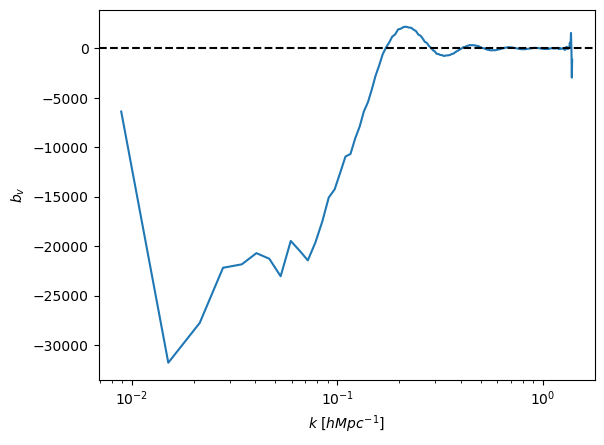

In [208]:
plt.semilogx(k, Pk0_X)
plt.axhline(0, c='k', ls='--')
plt.ylabel(r'$b_v$')
plt.xlabel(r'$k~[hMpc^{-1}]$');

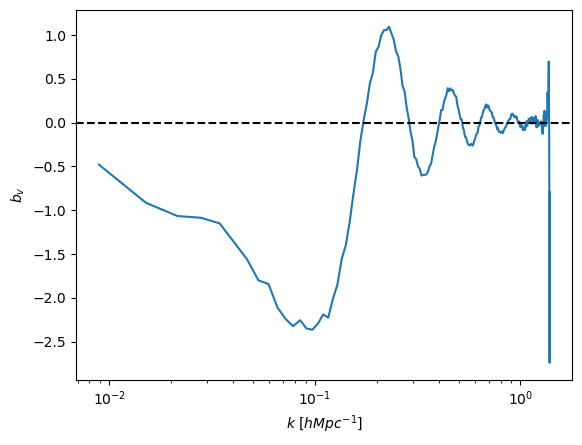

In [210]:
vbias = Pk0_X/Pk0
plt.semilogx(k, vbias)
plt.axhline(0, c='k', ls='--')
plt.ylabel(r'$b_v$')
plt.xlabel(r'$k~[hMpc^{-1}]$');

In [32]:
from scipy.spatial import KDTree

In [18]:
%%time
dm_pos_tree = KDTree(pos)

CPU times: user 37.5 s, sys: 2.97 s, total: 40.5 s
Wall time: 42.1 s


In [20]:
non_barrier_slt = (
    (lvoids[:,0]>lvoids[:,3]) & (lvoids[:,0]<BoxSize - lvoids[:,3]) &
    (lvoids[:,1]>lvoids[:,3]) & (lvoids[:,1]<BoxSize - lvoids[:,3]) &
    (lvoids[:,2]>lvoids[:,3]) & (lvoids[:,2]<BoxSize - lvoids[:,3])
)

In [21]:
lvoids_non_barrier = lvoids[non_barrier_slt]

Text(0.5, 0, 'Rv [Mpc/h]')

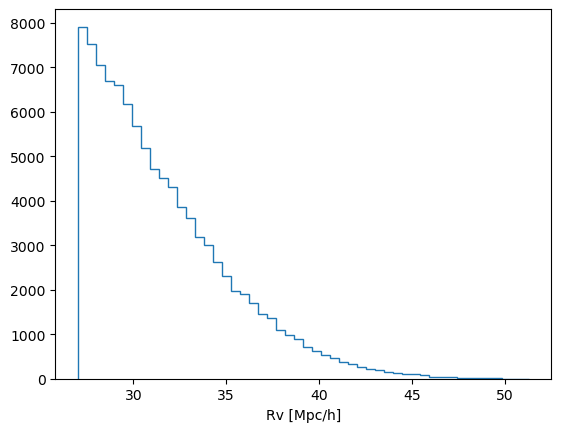

In [25]:
plt.hist(lvoids_non_barrier[:,3], bins=50, histtype='step');
plt.xlabel('Rv [Mpc/h]')

In [182]:
def process_voids(rvmin, rvmax):
    curr_vsslt = ( lvoids_non_barrier[:,3] > rvmin ) & ( lvoids_non_barrier[:,3] < rvmax )
    curr_voids = lvoids_non_barrier[curr_vsslt]
    print("Rv: {:.2f} - {:.2f}: {:d}".format(rvmin, rvmax, len(curr_voids)), flush=True)
    print("Finding dm parts inside voids", flush=True)
    results = dm_pos_tree.query_ball_point(curr_voids[:,:3], curr_voids[:,3])
    print("Get void effective velocity", flush=True)
    curr_voids_vel = []
    for i in range(len(results)):
        slt = results[i]
        curr_voids_vel.append((vel[slt]).mean(axis=0))
    curr_voids_vel = np.asarray(curr_voids_vel)

    return curr_voids, curr_voids_vel

In [186]:
rvmin_list = [27.5, 28.5, 29.5, 30.5, 31.5, 32.5, 33.5, 34.5]
rvmax_list = [28.5, 29.5, 30.5, 31.5, 32.5, 33.5, 34.5, 35.5]

In [187]:
%%time 
for idx, (rvmin, rvmax) in enumerate(zip(rvmin_list, rvmax_list)):
    curr_voids, curr_voids_vel = process_voids(rvmin, rvmax)
    print("Save to file.", flush=True)
    np.savez("/Users/suqikuai777/Dataspace/Quijote/large_voids_pos_vel_rvbin{}.npz".format(idx), 
             pos=curr_voids[:,:3], vel=curr_voids_vel, rv=curr_voids[:,3])

Rv: 27.50 - 28.50: 14923
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 28.50 - 29.50: 13660
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 29.50 - 30.50: 11968
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 30.50 - 31.50: 10088
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 31.50 - 32.50: 8899
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 32.50 - 33.50: 7417
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 33.50 - 34.50: 6105
Finding dm parts inside voids
Get void effective velocity
Save to file.
Rv: 34.50 - 35.50: 4739
Finding dm parts inside voids
Get void effective velocity
Save to file.
CPU times: user 1min 9s, sys: 20.7 s, total: 1min 30s
Wall time: 1min 33s


In [33]:
import Pk_library as PKL

In [34]:
def load_voids(rvbin_label):
    f = np.load("/Users/suqikuai777/Dataspace/Quijote/large_voids_pos_vel_rvbin{}.npz".format(rvbin_label))
    void_pos = f['pos']
    void_vel = f['vel']

    return void_pos, void_vel

In [35]:
def get_mom_map(pos_2d, vel_los, grid=256, BoxSize=1000.0, MAS='CIC'):
    H_map = np.zeros((grid, grid), dtype=np.float32)
    Nmean = len(pos_2d) / grid**2
    MASL.MA(pos_2d.astype(np.float32), H_map, BoxSize, MAS, W=vel_los.astype(np.float32)/Nmean)
    return H_map

In [177]:
def get_mom_map2(pos_3d_grid, vel_los_grid, Nmean, los_idx=2):
    ''' 
    0 for x-axis
    1 for y-axis
    2 for z-axis
    default is z-axis
    '''
    H_map = (pos_3d_grid * vel_los_grid / Nmean).sum(axis=los_idx)
    return H_map

In [140]:
grid = 256
BoxSize = 1000.0
MAS = 'CIC'

In [37]:
''' --- Generate dark matter momentum maps --- '''
''' --- Only need to run once --- '''
H_nxv_los_z = get_mom_map(pos[:,[0,1]], vel[:,2], grid=grid, BoxSize=BoxSize, MAS=MAS)
H_nxv_los_y = get_mom_map(pos[:,[0,2]], vel[:,1], grid=grid, BoxSize=BoxSize, MAS=MAS)
H_nxv_los_x = get_mom_map(pos[:,[1,2]], vel[:,0], grid=grid, BoxSize=BoxSize, MAS=MAS)

In [151]:
H_nxv_los_z2 = get_mom_map2(num, vel_map_z_truth, Nmean=len(pos[:,[0,1]])/grid**2, los_idx=2)

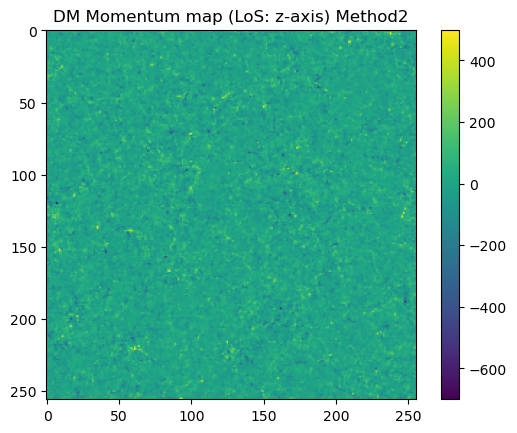

In [161]:
plt.title('DM Momentum map (LoS: z-axis) Method2')
plt.imshow(H_nxv_los_z2, vmin=-700, vmax=500)
plt.colorbar()

In [167]:
H_nxv_los_z_recon = get_mom_map2(num, vel_map_z_recon, Nmean=len(pos[:,[0,1]])/grid**2, los_idx=2)

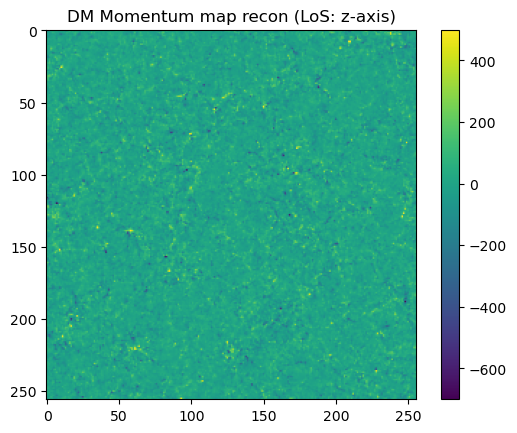

In [169]:
plt.title('DM Momentum map recon (LoS: z-axis)')
plt.imshow(H_nxv_los_z_recon, vmin=-700, vmax=500)
plt.colorbar()

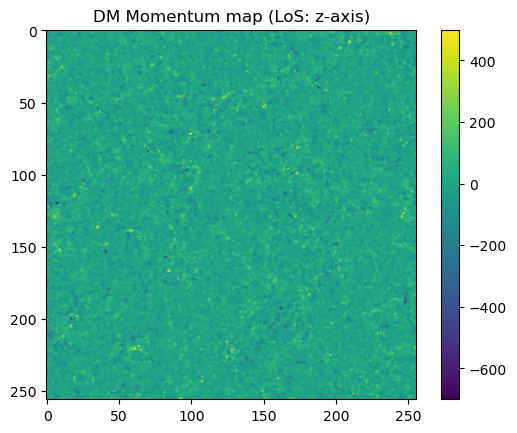

In [155]:
plt.title('DM Momentum map (LoS: z-axis)')
plt.imshow(H_nxv_los_z, vmin=-700, vmax=500)
plt.colorbar()

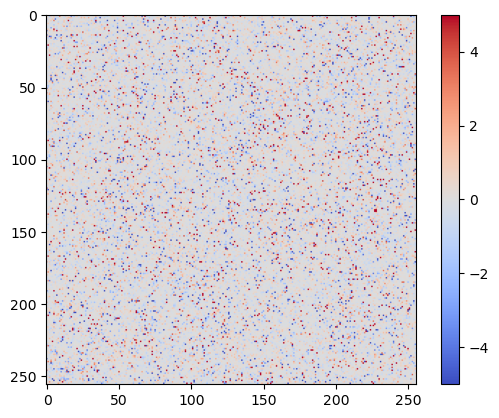

In [173]:
plt.imshow((H_nxv_los_z_recon - H_nxv_los_z)/H_nxv_los_z, cmap='coolwarm', vmin=-5, vmax=5)
plt.colorbar()

In [41]:
XPk_los_z_tot = []
for rvbin in range(7):
    void_pos, void_vel = load_voids(rvbin)
    ''' --- Generate void momentum maps --- '''
    H_nxv_v_los_z = get_mom_map(void_pos[:,[0,1]], void_vel[:,2], grid=grid, BoxSize=BoxSize, MAS=MAS)
    ''' --- Get P_mv_md --- '''
    XPk2D     = PKL.XPk_plane(H_nxv_los_z.astype(np.float32), H_nxv_v_los_z.astype(np.float32), BoxSize, MAS, MAS)
    k         = XPk2D.k        #k in h/Mpc
    XPk_los_z = XPk2D.XPk      #cross-Pk in (Mpc/h)^2
    XPk_los_z_tot.append(XPk_los_z)


Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds


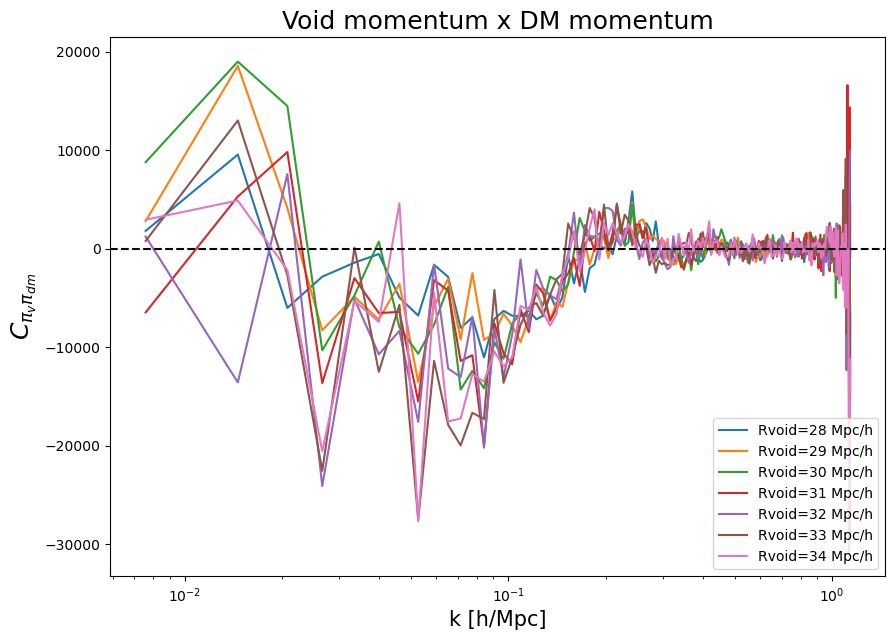

In [42]:
''' --- Plot --- '''
fig = plt.figure(figsize=(10,7))
plt.title('Void momentum x DM momentum', fontsize=18)
for i in range(7):
    plt.semilogx(k, XPk_los_z_tot[i], label='Rvoid={:d} Mpc/h'.format(28+i))
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{\pi_v \pi_{dm}}$', fontsize=18);

In [265]:
XPk_los_z_recon_tot = []
for rvbin in range(7):
    void_pos, void_vel = load_voids(rvbin)
    ''' --- Generate void momentum maps --- '''
    void_vel_z_recon_interp = np.zeros(void_pos.shape[0], dtype=np.float32)
    MASL.CIC_interp(vel_map_z_recon.astype(np.float32), BoxSize, void_pos.astype(np.float32), void_vel_z_recon_interp)
    # construct 3D density field
    H_nxv_v_los_z_recon = get_mom_map(void_pos[:,[0,1]], void_vel_z_recon_interp, grid=grid, BoxSize=BoxSize, MAS=MAS)
    ''' --- Get P_mv_md --- '''
    XPk2D     = PKL.XPk_plane(H_nxv_los_z.astype(np.float32), H_nxv_v_los_z_recon.astype(np.float32), BoxSize, MAS, MAS)
    k         = XPk2D.k        #k in h/Mpc
    XPk_los_z = XPk2D.XPk      #cross-Pk in (Mpc/h)^2
    XPk_los_z_recon_tot.append(XPk_los_z)


Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.01 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds


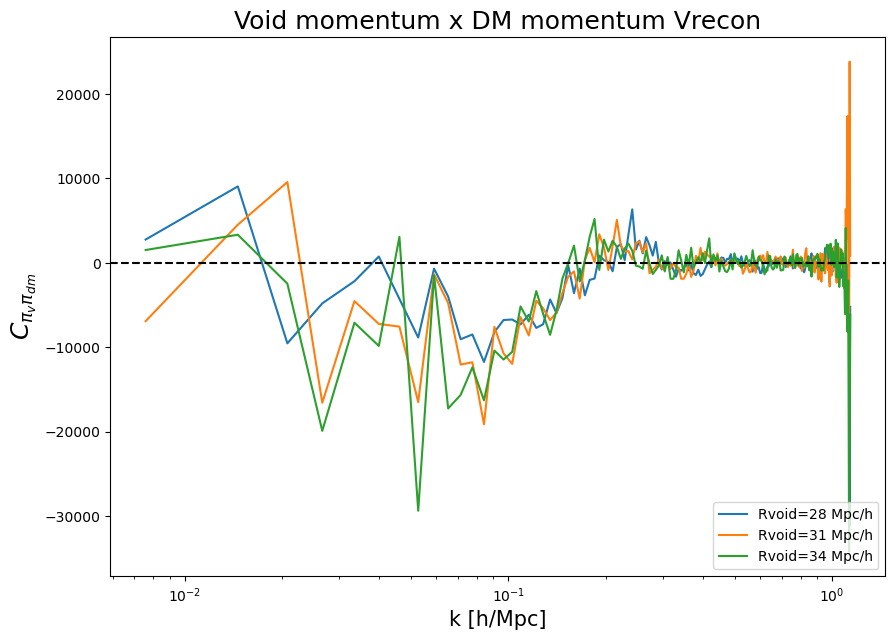

In [214]:
''' --- Plot --- '''
fig = plt.figure(figsize=(10,7))
plt.title('Void momentum x DM momentum Vrecon', fontsize=18)
for i in [0,3,6]:
    plt.semilogx(k, XPk_los_z_recon_tot[i], label='Rvoid={:d} Mpc/h'.format(28+i))
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{\pi_v \pi_{dm}}$', fontsize=18);

In [266]:
XPk_los_z_recon_h_tot = []
for rvbin in range(7):
    void_pos, void_vel = load_voids(rvbin)
    ''' --- Generate void momentum maps --- '''
    void_vel_z_recon_interp = np.zeros(void_pos.shape[0], dtype=np.float32)
    MASL.CIC_interp(vel_map_z_recon_h.astype(np.float32), BoxSize, void_pos.astype(np.float32), void_vel_z_recon_interp)
    # construct 3D density field
    H_nxv_v_los_z_recon = get_mom_map(void_pos[:,[0,1]], void_vel_z_recon_interp, grid=grid, BoxSize=BoxSize, MAS=MAS)
    ''' --- Get P_mv_md --- '''
    XPk2D     = PKL.XPk_plane(H_nxv_los_z.astype(np.float32), H_nxv_v_los_z_recon.astype(np.float32), BoxSize, MAS, MAS)
    k         = XPk2D.k        #k in h/Mpc
    XPk_los_z = XPk2D.XPk      #cross-Pk in (Mpc/h)^2
    XPk_los_z_recon_h_tot.append(XPk_los_z)


Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds

Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.00
Time taken = 0.00 seconds


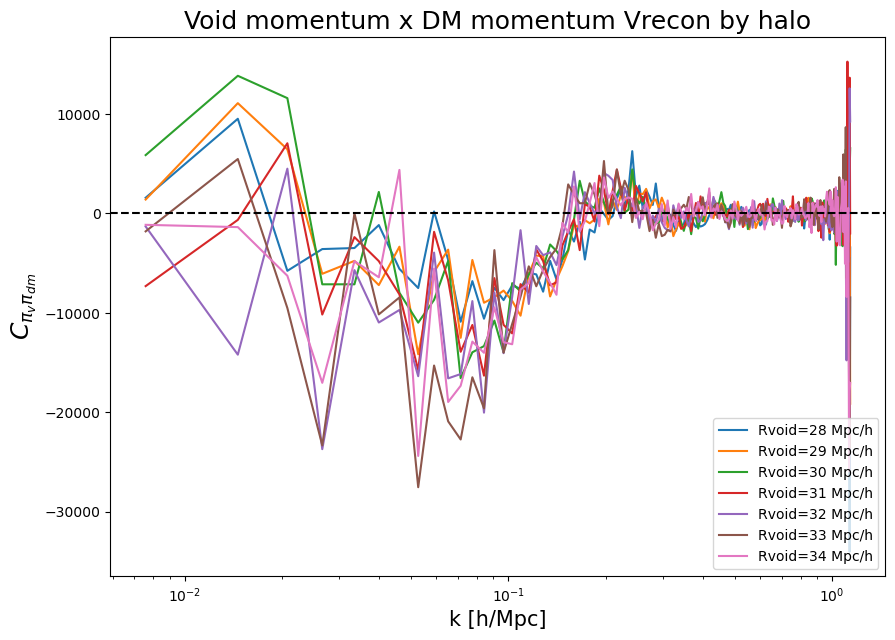

In [268]:
''' --- Plot --- '''
fig = plt.figure(figsize=(10,7))
plt.title('Void momentum x DM momentum Vrecon by halo', fontsize=18)
for i in range(7):
    plt.semilogx(k, XPk_los_z_recon_h_tot[i], label='Rvoid={:d} Mpc/h'.format(28+i))
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{\pi_v \pi_{dm}}$', fontsize=18);

In [256]:
void_pos, void_vel = load_voids(0)

In [277]:
void_vel_z_recon_interp = np.zeros(void_pos.shape[0], dtype=np.float32)
MASL.CIC_interp(vel_map_z_recon.astype(np.float32), BoxSize, void_pos.astype(np.float32), void_vel_z_recon_interp)

In [278]:
void_vel_z_recon_interp_h = np.zeros(void_pos.shape[0], dtype=np.float32)
MASL.CIC_interp(vel_map_z_recon_h.astype(np.float32), BoxSize, void_pos.astype(np.float32), void_vel_z_recon_interp_h)

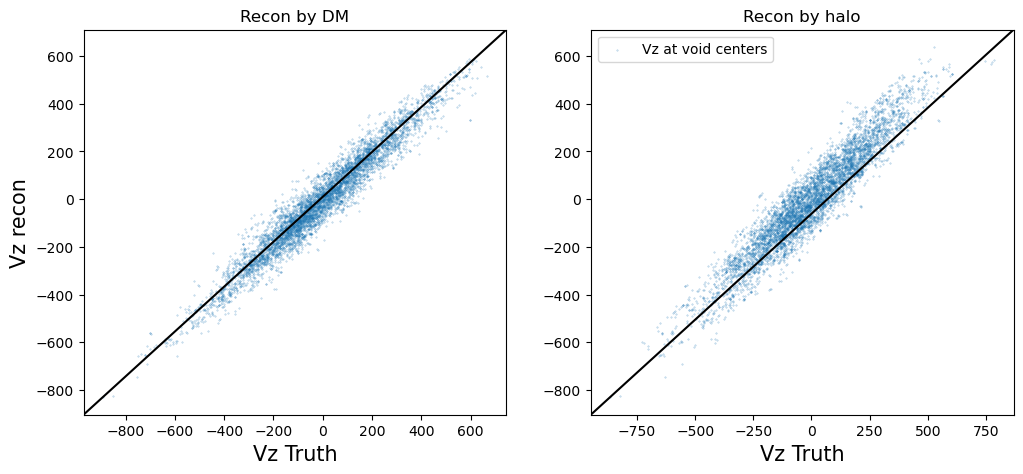

In [282]:
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(121)
ax.set_title('Recon by DM')
ax.scatter(void_vel_z_recon_interp, void_vel[:,2], s=0.1, alpha=0.5, label='Vz at void centers');
ax.plot([-1,1],[-1,1], transform=ax.transAxes, c='k')
ax.set_xlabel('Vz Truth', fontsize=15)
ax.set_ylabel('Vz recon', fontsize=15)
ax = fig.add_subplot(122)
ax.set_title('Recon by halo')
ax.scatter(void_vel_z_recon_interp_h, void_vel[:,2], s=0.1, alpha=0.5, label='Vz at void centers');
ax.plot([-1,1],[-1,1], transform=ax.transAxes, c='k')
ax.set_xlabel('Vz Truth', fontsize=15)
# ax.set_ylabel('Vz recon', fontsize=15)
plt.legend();

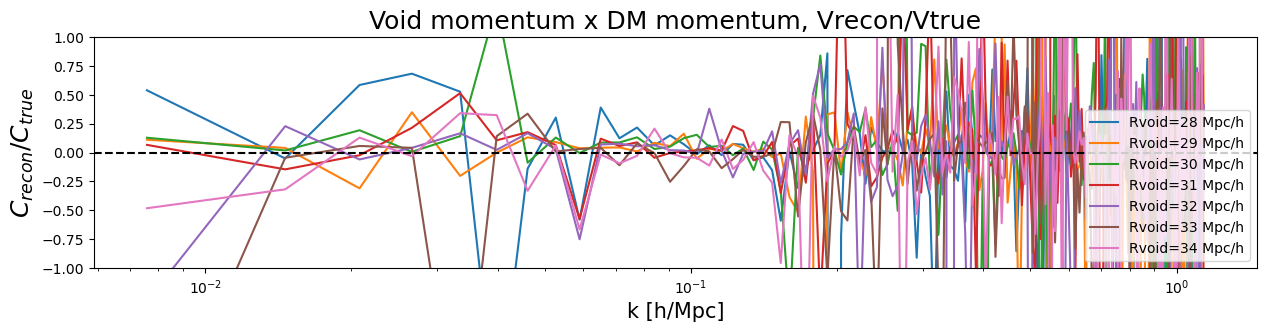

In [204]:
''' --- Plot --- '''
fig = plt.figure(figsize=(15,3))
plt.title('Void momentum x DM momentum, Vrecon/Vtrue', fontsize=18)
for i in range(7):
    plt.semilogx(k, XPk_los_z_recon_tot[i]/XPk_los_z_tot[i]-1, label='Rvoid={:d} Mpc/h'.format(28+i))
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.ylim(-1,1)
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{recon}/C_{true}$', fontsize=18);

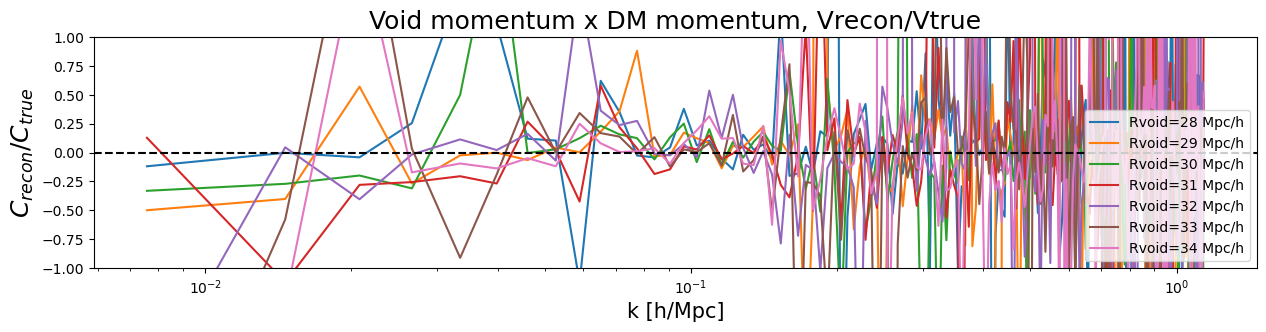

In [269]:
''' --- Plot --- '''
fig = plt.figure(figsize=(15,3))
plt.title('Void momentum x DM momentum, Vrecon/Vtrue', fontsize=18)
for i in range(7):
    plt.semilogx(k, XPk_los_z_recon_h_tot[i]/XPk_los_z_tot[i]-1, label='Rvoid={:d} Mpc/h'.format(28+i))
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.ylim(-1,1)
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{recon}/C_{true}$', fontsize=18);

In [236]:
void_pos_tot = []
void_vel_tot = []
for rvbin in range(7):
    void_pos, void_vel = load_voids(rvbin)
    void_pos_tot.append(void_pos)
    void_vel_tot.append(void_vel)

void_pos_tot = np.concatenate(void_pos_tot)
void_vel_tot = np.concatenate(void_vel_tot)

In [244]:
H_nxv_vtot_los_z = get_mom_map(void_pos_tot[:,[0,1]], void_vel_tot[:,2], grid=grid, BoxSize=BoxSize, MAS=MAS)
''' --- Get P_mv_md --- '''
XPk2D     = PKL.XPk_plane(H_nxv_los_z.astype(np.float32), H_nxv_vtot_los_z.astype(np.float32), BoxSize, MAS, MAS)
k         = XPk2D.k        #k in h/Mpc
XPk_vtot_los_z = XPk2D.XPk      #cross-Pk in (Mpc/h)^2


Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.01
Time taken = 0.01 seconds


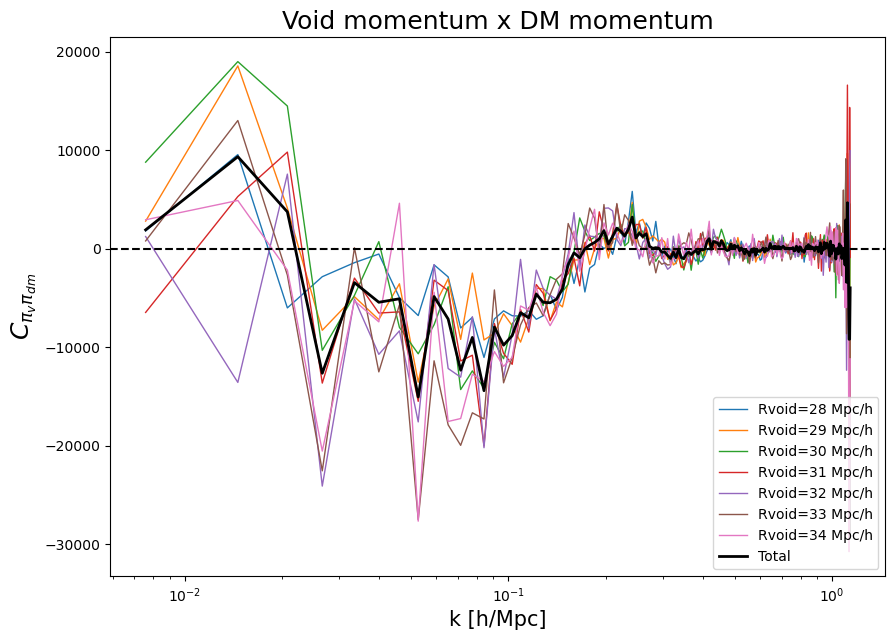

In [253]:
''' --- Plot --- '''
fig = plt.figure(figsize=(10,7))
plt.title('Void momentum x DM momentum', fontsize=18)
for i in range(7):
    plt.semilogx(k, XPk_los_z_tot[i], label='Rvoid={:d} Mpc/h'.format(28+i), lw=1)

plt.semilogx(k, XPk_vtot_los_z, label='Total', c='k', lw=2)
plt.axhline(0, c='k', ls='--')
plt.legend(loc='lower right')
plt.xlabel('k [h/Mpc]', fontsize=15)
plt.ylabel(r'$C_{\pi_v \pi_{dm}}$', fontsize=18);

In [221]:
H_nxv_h_los_z = get_mom_map(halo_pos[:,[0,1]], halo_vel[:,2], grid=grid, BoxSize=BoxSize, MAS=MAS)
''' --- Get P_mv_md --- '''
XPk2D     = PKL.XPk_plane(H_nxv_los_z.astype(np.float32), H_nxv_h_los_z.astype(np.float32), BoxSize, MAS, MAS)
k         = XPk2D.k        #k in h/Mpc
XPk_los_z = XPk2D.XPk      #cross-Pk in (Mpc/h)^2


Computing power spectra of the fields...
Time FFTS = 0.00
Time loop = 0.01
Time taken = 0.01 seconds


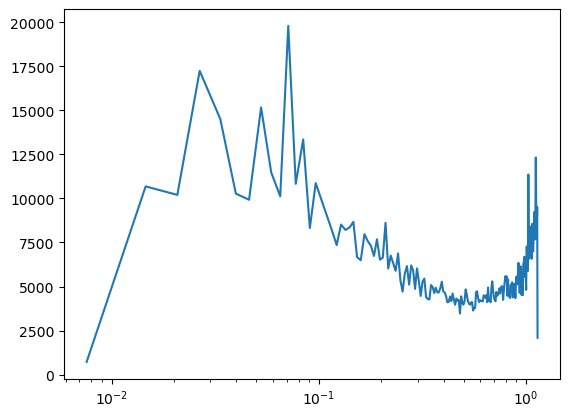

In [238]:
plt.semilogx(k, XPk_los_z)